<a href="https://colab.research.google.com/github/12mdkawsar/Telco-Customer-Churn-Analysis-project-and-report-01/blob/main/DATA_science.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [52]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import drive
drive.mount('/content/drive')

DATA_DIR    = '/content/drive/MyDrive/DAta science'
RAW_PATH    = f'{DATA_DIR}/Telco-Customer-Churn.csv'          # original (শুধু read)
CLEAN_PATH  = f'{DATA_DIR}/Telco-Customer-Churn-cleaned.csv'  # নতুন cleaned file

df = pd.read_csv(RAW_PATH)
print("Raw shape:", df.shape)
df.head()

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Raw shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [53]:
df.info()
print("\nMissing values (before conversion):")
print(df.isnull().sum().sum())
print("\nTotalCharges dtype:", df["TotalCharges"].dtype)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [54]:
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")

print("TotalCharges dtype:", df["TotalCharges"].dtype)
print("Missing TotalCharges:", df["TotalCharges"].isnull().sum())

# এই customer-রা কারা?
missing_rows = df[df["TotalCharges"].isnull()]
print("\nTenure of these customers:")
print(missing_rows["tenure"].value_counts())
missing_rows[["customerID", "tenure", "MonthlyCharges", "TotalCharges", "Churn"]]

TotalCharges dtype: float64
Missing TotalCharges: 11

Tenure of these customers:
tenure
0    11
Name: count, dtype: int64


,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,NaN,No
753,3115-CZMZD,0,20.25,NaN,No
936,5709-LVOEQ,0,80.85,NaN,No
1082,4367-NUYAO,0,25.75,NaN,No
1340,1371-DWPAZ,0,56.05,NaN,No
3331,7644-OMVMY,0,19.85,NaN,No
3826,3213-VVOLG,0,25.35,NaN,No
4380,2520-SGTTA,0,20.00,NaN,No
5218,2923-ARZLG,0,19.70,NaN,No
6670,4075-WKNIU,0,73.35,NaN,No


In [55]:

mask_new = df["TotalCharges"].isnull() & (df["tenure"] == 0)
df.loc[mask_new, "TotalCharges"] = 0
print("Filled with 0 (tenure = 0):", mask_new.sum())


num_cols = df.select_dtypes(include="number").columns
df[num_cols] = df[num_cols].fillna(df[num_cols].median())

# (c) Categorical missing  mode
cat_cols = df.select_dtypes(include=["object", "category", "string"]).columns
for col in cat_cols:
    if df[col].isnull().any():
        df[col] = df[col].fillna(df[col].mode()[0])

print("Total missing after cleaning:", df.isnull().sum().sum())

Filled with 0 (tenure = 0): 11
Total missing after cleaning: 0


In [56]:
print("Duplicate rows before:", df.duplicated().sum())
df = df.drop_duplicates()
print("Duplicate rows after :", df.duplicated().sum())
print("Cleaned shape:", df.shape)
df.to_csv(CLEAN_PATH, index=False)
print("Saved to:", CLEAN_PATH)

Duplicate rows before: 0
Duplicate rows after : 0
Cleaned shape: (7043, 21)
Saved to: /content/drive/MyDrive/DAta science/Telco-Customer-Churn-cleaned.csv


Dataset Shape: (7043, 21)

Columns: ['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecur

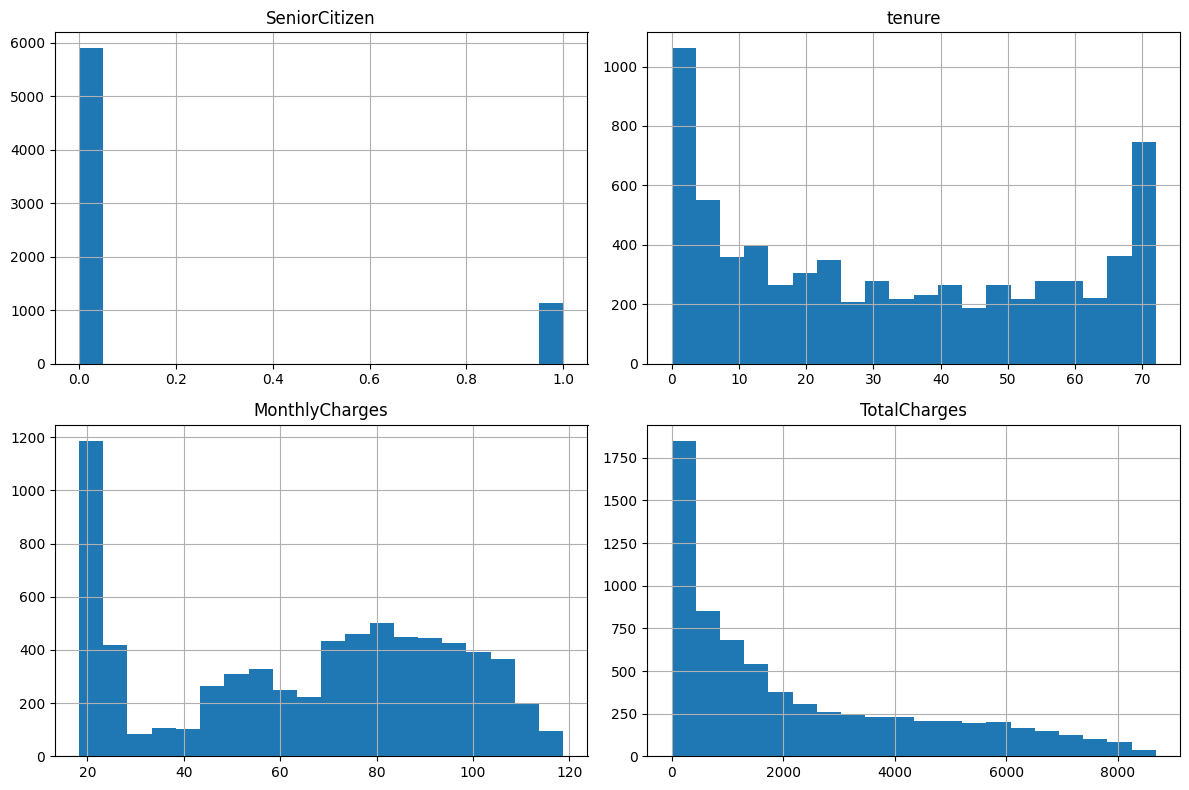

In [57]:
print("Dataset Shape:", df.shape)
print("\nColumns:", df.columns.tolist())
df.info()
df.describe()
df.hist(figsize=(12, 8), bins=20)
plt.tight_layout()
plt.show()

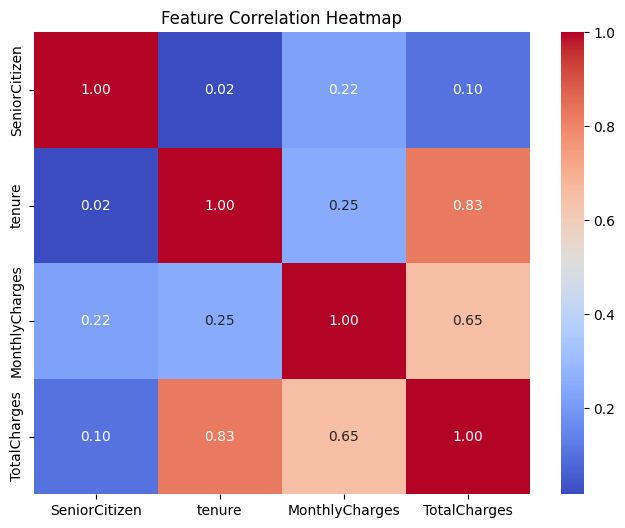

In [58]:
numeric_df = df.select_dtypes(include="number")

plt.figure(figsize=(8, 6))
sns.heatmap(numeric_df.corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Feature Correlation Heatmap")
plt.show()

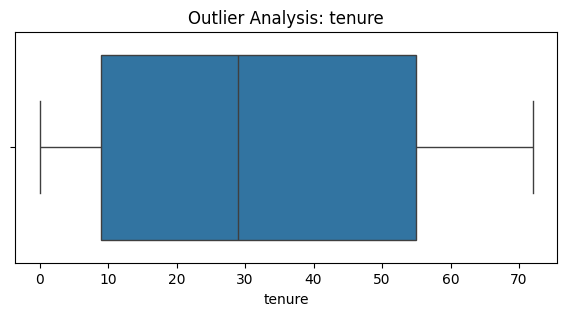

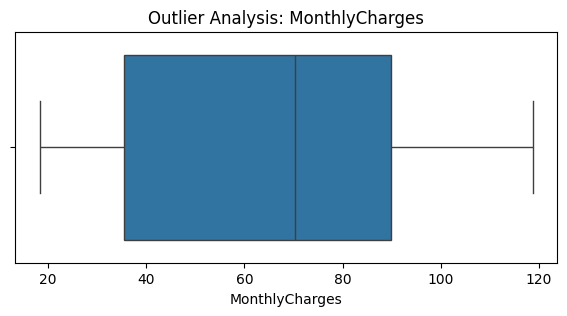

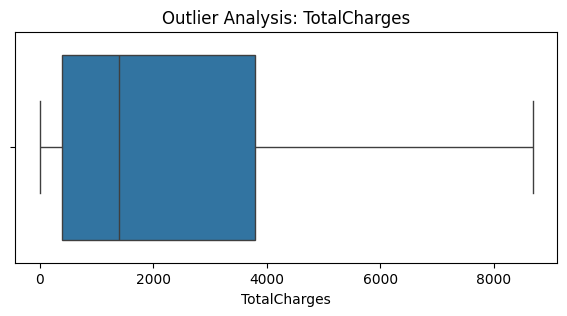

In [59]:
for col in ["tenure", "MonthlyCharges", "TotalCharges"]:
    plt.figure(figsize=(7, 3))
    sns.boxplot(x=df[col])
    plt.title(f"Outlier Analysis: {col}")
    plt.show()

Churn Count:
Churn
No     5174
Yes    1869
Name: count, dtype: int64

Churn Percentage:
Churn
No     73.46
Yes    26.54
Name: proportion, dtype: float64


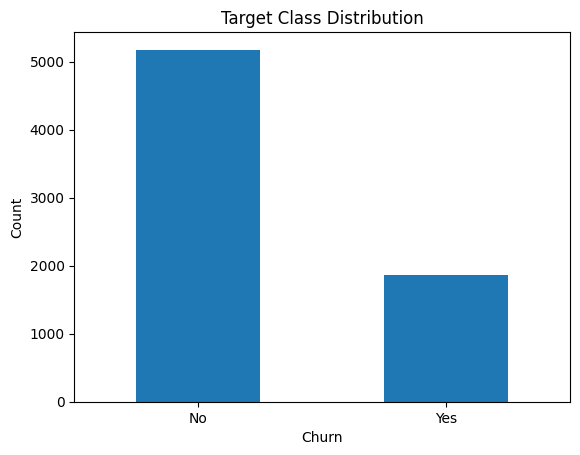

In [60]:
print("Churn Count:")
print(df["Churn"].value_counts())
print("\nChurn Percentage:")
print((df["Churn"].value_counts(normalize=True) * 100).round(2))

df["Churn"].value_counts().plot(kind="bar", title="Target Class Distribution")
plt.xlabel("Churn")
plt.ylabel("Count")
plt.xticks(rotation=0)
plt.show()

In [49]:
print("Average Tenure by Churn:")
print(df.groupby("Churn")["tenure"].mean().round(2))

print("\nAverage Monthly Charges by Churn:")
print(df.groupby("Churn")["MonthlyCharges"].mean().round(2))

print("\nAverage Total Charges by Churn:")
print(df.groupby("Churn")["TotalCharges"].mean().round(2))

Average Tenure by Churn:
Churn
No     37.57
Yes    17.98
Name: tenure, dtype: float64

Average Monthly Charges by Churn:
Churn
No     61.27
Yes    74.44
Name: MonthlyCharges, dtype: float64

Average Total Charges by Churn:
Churn
No     2549.91
Yes    1531.80
Name: TotalCharges, dtype: float64



Churn rate (%) by Contract:
Contract
Month-to-month    42.71
One year          11.27
Two year           2.83
Name: Churn, dtype: float64


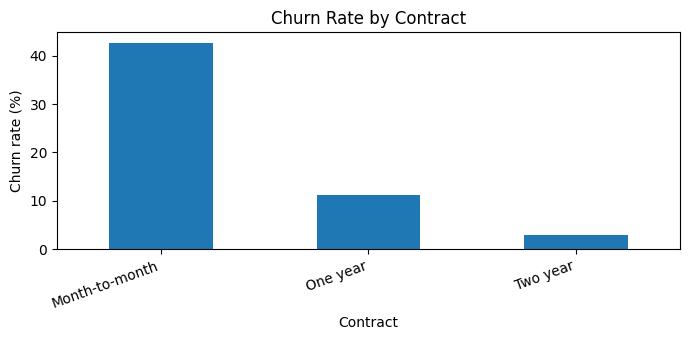


Churn rate (%) by InternetService:
InternetService
Fiber optic    41.89
DSL            18.96
No              7.40
Name: Churn, dtype: float64


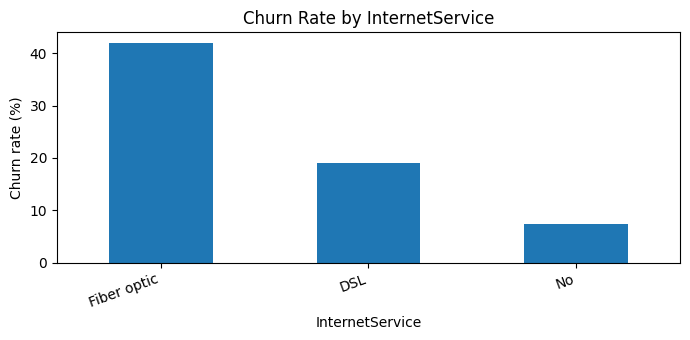


Churn rate (%) by PaymentMethod:
PaymentMethod
Electronic check             45.29
Mailed check                 19.11
Bank transfer (automatic)    16.71
Credit card (automatic)      15.24
Name: Churn, dtype: float64


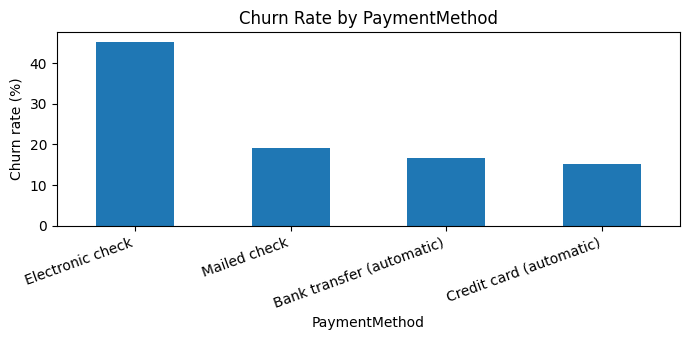

In [61]:
for col in ["Contract", "InternetService", "PaymentMethod"]:
    rate = (df.groupby(col)["Churn"]
              .apply(lambda s: (s == "Yes").mean() * 100)
              .sort_values(ascending=False))
    print(f"\nChurn rate (%) by {col}:")
    print(rate.round(2))

    plt.figure(figsize=(7, 3.5))
    rate.plot(kind="bar")
    plt.ylabel("Churn rate (%)")
    plt.title(f"Churn Rate by {col}")
    plt.xticks(rotation=20, ha="right")
    plt.tight_layout()
    plt.show()

In [62]:
print("Shape            :", df.shape)
print("Missing values   :", df.isnull().sum().sum())
print("Duplicate rows   :", df.duplicated().sum())
print("TotalCharges type:", df["TotalCharges"].dtype)

Shape            : (7043, 21)
Missing values   : 0
Duplicate rows   : 0
TotalCharges type: float64


In [63]:
# Business Analysis: Customer Churn

import pandas as pd

# Contract  Churn Rate
contract_churn = (
    df.groupby("Contract")["Churn"]
    .apply(lambda x: (x == "Yes").mean() * 100)
    .round(2)
    .sort_values(ascending=False)
)

print("Churn Rate by Contract:")
print(contract_churn)

# Internet Service  Churn Rate
internet_churn = (
    df.groupby("InternetService")["Churn"]
    .apply(lambda x: (x == "Yes").mean() * 100)
    .round(2)
    .sort_values(ascending=False)
)

print("\nChurn Rate by Internet Service:")
print(internet_churn)

# Payment Method  Churn Rate
payment_churn = (
    df.groupby("PaymentMethod")["Churn"]
    .apply(lambda x: (x == "Yes").mean() * 100)
    .round(2)
    .sort_values(ascending=False)
)

print("\nChurn Rate by Payment Method:")
print(payment_churn)

Churn Rate by Contract:
Contract
Month-to-month    42.71
One year          11.27
Two year           2.83
Name: Churn, dtype: float64

Churn Rate by Internet Service:
InternetService
Fiber optic    41.89
DSL            18.96
No              7.40
Name: Churn, dtype: float64

Churn Rate by Payment Method:
PaymentMethod
Electronic check             45.29
Mailed check                 19.11
Bank transfer (automatic)    16.71
Credit card (automatic)      15.24
Name: Churn, dtype: float64



TiTel:Telco-Customer-Churn-Analysis(Report,project)

# Telco Customer Churn: Data Cleaning and Analysis

**Name:** [M D.kawsar]    **Date:** [24.10.26]

## 1. Introduction
Churn means a customer stops using a company's service. If a company knows why customers leave, it can try to keep them. In this project I used the Telco Customer Churn dataset to clean the data and look for patterns that are linked with churn. [Dataset source: Kaggle / IBM sample data]

## 2. About the Dataset
The dataset has **7,043 customers** and **21 columns**. The target column is `Churn` (Yes or No). The other columns include customer details (gender, senior citizen, partner, dependents), services (internet service, tech support, streaming) and account details (contract type, payment method, tenure, monthly charges, total charges).

## 3. Data Cleaning
**Wrong data type.** The `TotalCharges` column was stored as text, so it showed no missing values at first. I changed it to a number using `pd.to_numeric`. After that, **11 missing values** appeared (they were blank spaces before).

**Handling the missing values.** All 11 customers had a `tenure` of 0, which means they had just joined and had not been billed yet. So I filled their `TotalCharges` with **0** instead of using an average.

**Duplicates.** I checked for duplicate rows and found **none**.

After cleaning, the data had no missing values and the shape stayed (7043, 21). I saved the cleaned data in a new file and did not change the original file.

## 4. Analysis and Findings

**Churn rate.** Out of 7,043 customers, 1,869 left (**26.54%**) and 5,174 stayed (73.46%). The data is imbalanced because there are many more "No" than "Yes".

**Tenure and charges.**

| | Stayed | Left |
|---|---|---|
| Average tenure (months) | 37.57 | 17.98 |
| Average monthly charges | $61.27 | $74.44 |
| Average total charges | $2,549.91 | $1,531.80 |

Customers who left had been with the company for about half as long, and they paid more each month.

**Contract type.** Month-to-month customers left the most (**42.71%**). The rate was 11.27% for one-year contracts and only 2.83% for two-year contracts.

**Internet service.** Fiber optic customers had the highest churn (**41.89%**), compared with DSL (18.96%) and customers with no internet (7.40%).

**Payment method.** Customers paying by electronic check left the most (**45.29%**). The other methods were much lower: mailed check 19.11%, bank transfer 16.71% and credit card 15.24%.

**Charts.**### Charts and Observations

1. **Histogram:** The numerical features have different distributions. Tenure and MonthlyCharges show variations among customers.

2. **Heatmap:** Tenure and TotalCharges show a positive correlation, meaning customers with longer tenure generally have higher total charges.

3. **Boxplot:** Some numerical columns, such as MonthlyCharges and TotalCharges, may contain outliers. These values should be checked before further analysis.
## 5. Conclusion
New customers, month-to-month contract holders, fiber optic users and electronic check payers are the groups most likely to leave. The company could offer discounts or longer contracts to new customers and look into why fiber optic users are unhappy. It could also encourage automatic payment methods.

## 6. Limitations
This project only covers cleaning and exploring the data. It does not build a prediction model. The patterns show a link with churn, but they do not prove the cause. A next step would be to train a model such as logistic regression or random forest.

